In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Imports

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score, cohen_kappa_score, roc_curve
)

import joblib


# Load Cleaned Dataset

In [3]:
DATA_PATH = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Data/Assamese_Movie_Review_Cleaned_8987.csv"

df = pd.read_csv(DATA_PATH)
df.head()


,ID,Reviews,Sentiment
0,0,বোকা নাটক,negative
1,1,নাটকখন বৰ ধুনীয়া আছিল,positive
2,2,এখন ভাল ঘৰ এনে হব লাগে,positive
3,3,এইটো আশ্চৰ্যকৰ আছিল,positive
4,4,মই বহুদিন অপেক্ষা কৰি আছো. অৱশেষত দেখিলো. কেৱল...,positive


In [4]:
# Remove corrupted row with header leakage
df = df[~((df['ID'] == 4227) & (df['Reviews'] == 'Reviews'))].reset_index(drop=True)

print("Dataset shape after removing corrupted row:", df.shape)


Dataset shape after removing corrupted row: (8986, 3)


In [5]:
assert not ((df['Reviews'] == 'Reviews') | (df['Sentiment'].isna())).any(), \
    "Corrupted rows still exist in the dataset"


In [6]:
df['Sentiment'] = (
    df['Sentiment']
    .astype(str)
    .str.strip()
    .str.lower()
)


# Label Encoding

In [7]:
df['label'] = df['Sentiment'].map({'negative': 0, 'positive': 1})

df[['Sentiment', 'label']].drop_duplicates()


,Sentiment,label
0,negative,0
1,positive,1


# Train-Validation Split

In [8]:
X_train, X_val, y_train, y_val = train_test_split(
    df['Reviews'],
    df['label'],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)
len(X_train), len(X_val)

(7188, 1798)

# Optimized Tf-Idf Feature Extraction

1.Bigrams capture sentiment phrases

2.Sublinear_tf stabilizes long reviews

3.min_df=3 removes noise

4.Works well for Assamese morphology



In [10]:
tfidf = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 2),
    max_features=50000,
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)

# Fill NaN values with empty strings before TF-IDF transformation
X_train_cleaned = X_train.fillna('')
X_val_cleaned   = X_val.fillna('')

X_train_tfidf = tfidf.fit_transform(X_train_cleaned)
X_val_tfidf   = tfidf.transform(X_val_cleaned)

X_train_tfidf.shape, X_val_tfidf.shape

((7188, 3888), (1798, 3888))

1.   Training set: There are 7188 samples and 3888 unique features (words/bigrams) after TF-IDF transformation.
2.   Validation set: There are 1798 samples and 3888 features, consistent with the features learned from the training data.




# Train SVM

We use LinearSVC, which is:

1. Faster

2. More stable for text

3. Standard in sentiment analysis

In [11]:
svm = LinearSVC(
    C=1.0,
    class_weight='balanced',
    random_state=42,
    max_iter=5000
)

svm.fit(X_train_tfidf, y_train)


LinearSVC(class_weight='balanced', max_iter=5000, random_state=42)

# Probability Calibration

SVM does not output probabilities natively.
But ROC–AUC requires probabilities.

In [12]:
svm_calibrated = CalibratedClassifierCV(
    svm,
    method='sigmoid',
    cv=5
)

svm_calibrated.fit(X_train_tfidf, y_train)


CalibratedClassifierCV(cv=5,
                       estimator=LinearSVC(class_weight='balanced',
                                           max_iter=5000, random_state=42))

# Evaluation Metrics

In [13]:
y_val_preds = svm_calibrated.predict(X_val_tfidf)
y_val_probs = svm_calibrated.predict_proba(X_val_tfidf)[:, 1]

metrics = {
    "accuracy": accuracy_score(y_val, y_val_preds),
    "macro_f1": f1_score(y_val, y_val_preds, average='macro'),
    "macro_precision": precision_score(y_val, y_val_preds, average='macro'),
    "macro_recall": recall_score(y_val, y_val_preds, average='macro'),
    "roc_auc": roc_auc_score(y_val, y_val_probs),
    "cohen_kappa": cohen_kappa_score(y_val, y_val_preds)
}

metrics


{'accuracy': 0.8503893214682982,
 'macro_f1': 0.8365606440766742,
 'macro_precision': 0.8431887170380159,
 'macro_recall': 0.8314938726011658,
 'roc_auc': np.float64(0.9313506606101869),
 'cohen_kappa': np.float64(0.6733862853330344)}

# Confusion Matrix

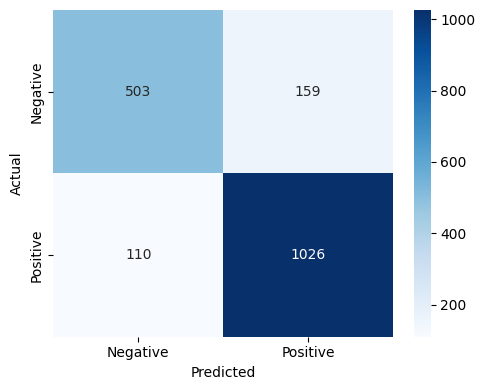

In [14]:
CM_PATH = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/Confusion Matrix/"
os.makedirs(CM_PATH, exist_ok=True)

cm = confusion_matrix(y_val, y_val_preds)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()

plt.savefig(f"{CM_PATH}svm_confusion_matrix.svg", format="svg")
plt.show()


# ROC-AUC Curve

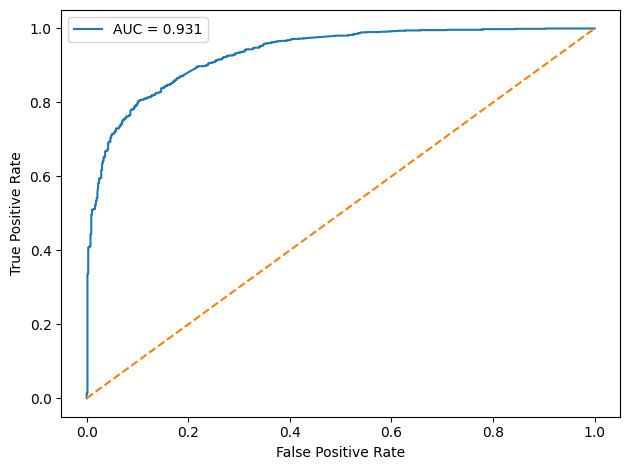

In [15]:
fpr, tpr, _ = roc_curve(y_val, y_val_probs)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {metrics['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/svm_roc_curve.svg",
    format="svg"
)
plt.show()


# Save SVM Model and Tf-Idf Vectorizer

In [16]:
MODEL_PATH = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Models/SVM/"
os.makedirs(MODEL_PATH, exist_ok=True)

joblib.dump(svm_calibrated, f"{MODEL_PATH}svm_model.joblib")
joblib.dump(tfidf, f"{MODEL_PATH}tfidf_vectorizer.joblib")

print("SVM model and vectorizer saved successfully.")


SVM model and vectorizer saved successfully.
